# 08 Gradient boosting, deviation target, 09:00 cutoff

Same model, folds and scoring as notebook 07, but the target is the deviation from the 28-day same-period median, `y_dev = price - med28_same`. The forecast is `med28_same + predicted deviation`. The idea: the model no longer has to learn the absolute level, which trees extrapolate poorly when prices drift. Compared with the baseline and with the direct-target model from 07.

## Init

In [1]:
import sys
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

from _eval import make_folds, score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

T = pd.read_parquet("outputs/feature_table_dev.parquet")
D9 = T[T["cutoff_hour"] == 9].reset_index(drop=True)
days = pd.DatetimeIndex(sorted(D9["day"].unique()))
folds_exp = make_folds(days, 28, 17, 1)
folds_sli = make_folds(days, 28, 17, 1, train_window=180)
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds_exp]))
VAL = D9["day"].isin(val_days_all)

CAL = ["hour_frac", "weekday", "is_weekend", "bank_holiday", "doy_sin", "doy_cos", "clock_change_day"]
HIST = ["d2_same", "med7_same", "med28_same", "level7", "level28", "level24h", "level_gap"]
FC = ["demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw", "wind_total_mw",
      "demand_age_h", "wind_age_h", "emb_age_h", "demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev"]
MG = ["mgn_min_demand", "mgn_surplus", "mgn_constrained", "mgn_gen_avail", "mgn_ic_import"]
SETS = {"A": CAL + HIST, "B": CAL + HIST + FC, "C": CAL + HIST + FC + MG}
HP = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=100,
          l2_regularization=1.0, early_stopping=False, random_state=0)
print(len(D9), "rows;", int(VAL.sum()), "validation rows;", D9["y_dev"].notna().mean().round(3), "share with a deviation target")

32351 rows; 22847 validation rows; 0.978 share with a deviation target


## 1. Run

Six configurations: feature sets A, B, C, expanding and sliding windows, absolute-error loss. Training rows need both a price and a 28-day median (the first 28 days of data have none). The 07 results are loaded from `outputs/` for the paired comparison with the direct target.

In [2]:
def run_cv(cols, folds, loss="absolute_error"):
    dev = pd.Series(np.nan, index=D9.index)
    for f in folds:
        tr = D9[D9["day"].isin(f["train_days"]) & D9["y_dev"].notna()]
        va = D9[D9["day"].isin(f["val_days"])]
        m = HistGradientBoostingRegressor(loss=loss, **HP).fit(tr[cols], tr["y_dev"])
        dev.loc[va.index] = m.predict(va[cols])
    return D9["med28_same"] + dev

CFG = {}
for s in "ABC":
    for w, folds in [("expanding", folds_exp), ("sliding", folds_sli)]:
        CFG[f"{s} dev {w}"] = run_cv(SETS[s], folds)
P = pd.DataFrame(CFG)
old = pd.read_parquet("outputs/cv_preds_gbm_direct_0900.parquet")
P7 = D9[["period_start"]].merge(old.drop(columns=["day", "price", "med28_same"]), on="period_start", how="left")
P7.index = D9.index
DIRECT = {c: P7[c] for c in P7.columns if c != "period_start"}
P["day"] = D9["day"]; P["period_start"] = D9["period_start"]; P["price"] = D9["price"]; P["med28_same"] = D9["med28_same"]
P.loc[VAL].to_parquet("outputs/cv_preds_gbm_dev_0900.parquet", index=False)
print(list(CFG)); print(list(DIRECT))

['A dev expanding', 'A dev sliding', 'B dev expanding', 'B dev sliding', 'C dev expanding', 'C dev sliding']
['A abs expanding', 'A abs sliding', 'B abs expanding', 'B abs sliding', 'C abs expanding', 'C abs sliding', 'C sq expanding', 'C sq sliding']


## 2. Pooled scores

Deviation-target models next to the baseline and to the corresponding direct-target models from 07.

In [3]:
def sc(pred):
    return score(D9[VAL].assign(pred=pred[VAL]), "pred")
rows = {"28-day median (baseline)": sc(D9["med28_same"])}
for s in "ABC":
    for w in ["expanding", "sliding"]:
        rows[f"{s} direct {w}"] = sc(DIRECT[f"{s} abs {w}"])
        rows[f"{s} dev    {w}"] = sc(P[f"{s} dev {w}"])
R = pd.DataFrame(rows).T
print(R[["MAE", "RMSE", "bias", "hit_top8", "hit_bot8", "MAE_top10", "MAE_bot10"]].round(3).to_string())

                             MAE    RMSE    bias  hit_top8  hit_bot8  MAE_top10  MAE_bot10
28-day median (baseline)  30.200  42.230   1.890     0.462     0.322     49.103     82.293
A direct expanding        32.631  44.046  -2.570     0.461     0.326     57.511     72.251
A dev    expanding        32.285  43.461  -3.068     0.468     0.325     57.834     71.320
A direct sliding          36.117  47.918 -10.205     0.459     0.304     63.311     70.736
A dev    sliding          36.994  48.799 -11.508     0.467     0.299     63.610     69.140
B direct expanding        28.775  38.678  -3.698     0.491     0.359     54.398     47.506
B dev    expanding        28.734  38.509  -4.593     0.484     0.361     51.992     45.997
B direct sliding          29.100  39.063  -4.306     0.475     0.346     54.214     49.935
B dev    sliding          29.823  40.232  -4.558     0.474     0.346     52.983     51.449
C direct expanding        28.571  38.521  -3.588     0.488     0.364     53.836     46.902

## 3. Paired by fold

Per-fold differences, as in 07: against the baseline, and against the direct model with the same features and window. Entries are mean difference +/- standard error (folds where the deviation model is better).

In [4]:
def fold_table(pred):
    rows = []
    for f in folds_exp:
        d = D9[D9["day"].isin(f["val_days"])].assign(pred=pred)
        s = score(d, "pred"); s["fold"] = f["fold"]; rows.append(s)
    return pd.DataFrame(rows).set_index("fold")

BASE = fold_table(D9["med28_same"])
LOWER_BETTER = {"MAE": True, "RMSE": True, "hit_top8": False, "hit_bot8": False, "MAE_top10": True, "MAE_bot10": True}

def paired(ft, ref):
    out = {}
    for m, low in LOWER_BETTER.items():
        d = ft[m] - ref[m]
        w = (d < 0).sum() if low else (d > 0).sum()
        fmt = "{:+.2f}" if m.startswith(("MAE", "RMSE")) else "{:+.3f}"
        out[m] = f"{fmt.format(d.mean())} +/- {d.std() / np.sqrt(len(d)):.2f} ({w}/17)"
    return out

FT = {n: fold_table(P[n]) for n in CFG}
FT_direct = {n: fold_table(v) for n, v in DIRECT.items()}
print("deviation model vs baseline")
print(pd.DataFrame({n: paired(FT[n], BASE) for n in CFG}).T.to_string())
print()
print("deviation model vs direct model (same features, window)")
cmp = {}
for s in "ABC":
    for w in ["expanding", "sliding"]:
        cmp[f"{s} {w}"] = paired(FT[f"{s} dev {w}"], FT_direct[f"{s} abs {w}"])
print(pd.DataFrame(cmp).T.to_string())

deviation model vs baseline
                                    MAE                    RMSE                 hit_top8                 hit_bot8               MAE_top10                MAE_bot10
A dev expanding   +2.08 +/- 0.69 (4/17)   +1.23 +/- 0.83 (6/17)   +0.006 +/- 0.00 (9/17)   +0.003 +/- 0.01 (8/17)   +1.94 +/- 2.84 (8/17)   -9.90 +/- 3.70 (11/17)
A dev sliding     +6.79 +/- 1.71 (1/17)   +6.35 +/- 1.58 (2/17)  +0.004 +/- 0.00 (10/17)   -0.023 +/- 0.01 (3/17)  +11.24 +/- 3.63 (4/17)  -15.01 +/- 3.80 (14/17)
B dev expanding  -1.47 +/- 0.82 (10/17)  -3.32 +/- 1.01 (13/17)  +0.022 +/- 0.00 (15/17)  +0.039 +/- 0.01 (14/17)  -3.48 +/- 2.44 (10/17)  -31.48 +/- 4.45 (16/17)
B dev sliding     -0.38 +/- 0.75 (9/17)  -1.76 +/- 0.81 (11/17)  +0.012 +/- 0.01 (11/17)  +0.024 +/- 0.01 (12/17)  -1.29 +/- 2.47 (10/17)  -27.84 +/- 3.87 (17/17)
C dev expanding  -1.47 +/- 0.79 (10/17)  -3.11 +/- 1.05 (13/17)  +0.021 +/- 0.01 (14/17)  +0.030 +/- 0.01 (12/17)  -3.58 +/- 2.43 (10/17)  -31.67 +/- 4.42 (1

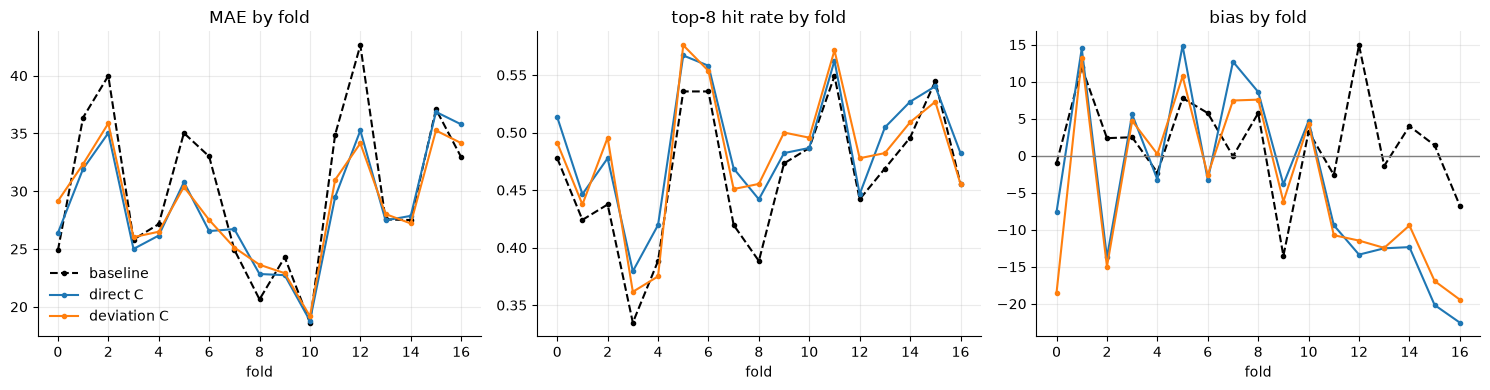

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for n, ft, st in [("baseline", BASE, "k--"), ("direct C", FT_direct["C abs expanding"], "-"), ("deviation C", FT["C dev expanding"], "-")]:
    axes[0].plot(ft["MAE"], st, marker="o", ms=3, label=n)
    axes[1].plot(ft["hit_top8"], st, marker="o", ms=3, label=n)
    axes[2].plot(ft["bias"], st, marker="o", ms=3, label=n)
for ax, t in zip(axes, ["MAE by fold", "top-8 hit rate by fold", "bias by fold"]):
    ax.set_title(t); ax.set_xlabel("fold")
axes[2].axhline(0, color="grey", lw=1); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Importance

Permutation importance for set C (deviation target, expanding window), same two folds as in 07. Importance is the increase in MAE of the final price forecast when a feature is shuffled.

In [6]:
def perm(fold_id, cols):
    f = folds_exp[fold_id]
    tr = D9[D9["day"].isin(f["train_days"]) & D9["y_dev"].notna()]
    va = D9[D9["day"].isin(f["val_days"]) & D9["price"].notna()]
    m = HistGradientBoostingRegressor(loss="absolute_error", **HP).fit(tr[cols], tr["y_dev"])
    base = va["med28_same"].to_numpy()
    class W:
        def fit(self, *a): return self
        def predict(self, X): return base + m.predict(X)
    r = permutation_importance(W(), va[cols], va["price"], scoring=lambda est, X, y: -np.abs(est.predict(X) - y).mean(),
                               n_repeats=5, random_state=0)
    return pd.Series(r.importances_mean, index=cols)
imp = pd.DataFrame({"fold 8": perm(8, SETS["C"]), "fold 16": perm(16, SETS["C"])}).round(2)
print(imp.sort_values("fold 16", ascending=False).head(14).to_string())

                fold 8  fold 16
demand_mw         1.28     2.91
emb_wind_mw      -1.00     2.30
emb_solar_mw     -0.10     1.49
med28_same        1.07     1.19
wind_total_mw    -0.96     0.25
mgn_min_demand   -0.58     0.24
wind_mw          -0.82     0.22
level_gap         0.08     0.10
emb_wind_rev     -0.00     0.08
med7_same        -0.01     0.03
emb_solar_rev    -0.02     0.03
hour_frac         0.17     0.03
doy_sin           0.01     0.02
weekday          -0.02     0.01


## Findings (09:00 cutoff, 17 folds)

- **The deviation target does not improve on the direct target.** Against the direct model with the same features and window, the differences are within noise for the settings that work best: B expanding MAE -0.12 (std error 0.29), C expanding +0.15 (0.31), hit rates within 0.01. Pooled: B expanding 28.73 vs 28.85, C expanding 28.73 vs 28.58 (baseline 30.20). With the sliding window the deviation model is worse (MAE +0.6 to +0.9 against the direct model, better in only 4-6 of 17 folds).
- **The weather/demand gain is the same either way.** Deviation B/C expanding: MAE -1.5 against the baseline (std error 0.8), RMSE -3.1 to -3.3 (1.0), top-8 hit +0.02 (13-15 of 17 folds), bottom-8 +0.03 to +0.04. So the result in 07 is not an artefact of how the target is defined.
- **The hypothesis for set A was only partly right.** The deviation target improves A against the direct version (MAE -0.45, std error 0.18, 13/17 folds), but A is still worse than the baseline (+2.1, 4/17). A model with only calendar and history features should at best reproduce the baseline; being 2 pounds worse means it is fitting noise. The sliding window makes this much worse (+6.8).
- **The negative bias did not go away** (-4.4 for C expanding). So it is not caused by level extrapolation. A forecast of the conditional median on a right-skewed price will sit below the mean, so some negative bias is expected under absolute-error loss; I have not checked whether the share of prices above the forecast is near 50%.
- **Importance.** Demand, embedded wind and embedded solar again carry the signal; `med28_same` matters on fold 16 (1.2) and fold 8 (1.1). Several features are slightly negative on fold 8 (shuffling helps), another sign of overfitting.
- **Takeaway.** Target design is not the bottleneck. Set A being worse than the baseline points to the model fitting noise, which makes regularisation (fewer/shallower trees, larger leaves, fewer features) the next thing to examine, together with seed sensitivity. Quantile models still address the tails directly.
